In [1]:
# ============================================
# YUVA PLATFORM INTERNSHIP - PROJECT 2
# Data Cleaning and Pre-Processing
# ============================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define project paths
PROJECT_DIR = Path.cwd().parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "raw"
    / "online_retail_II.xlsx"
)

# Check whether the dataset exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Check the filename and project folder structure."
    )

print("Project 2: Data Cleaning and Pre-Processing")
print("-" * 50)
print(f"Dataset path: {DATA_PATH}")
print("Libraries imported successfully!")

ModuleNotFoundError: No module named 'numpy'

In [2]:
# Inspect the Excel workbook

excel_file = pd.ExcelFile(DATA_PATH)

print("Available sheets:")
print(excel_file.sheet_names)

Available sheets:
['Year 2009-2010', 'Year 2010-2011']


In [3]:
# Load the workbook into a DataFrame

df = pd.read_excel(
    DATA_PATH,
    sheet_name=excel_file.sheet_names[0]
)

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

df.head()

Dataset loaded successfully!
Number of rows: 525,461
Number of columns: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
# Inspect column names and data types

print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


In [5]:
# Inspect numerical columns

df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,525461.0,10.337667,-9600.0,1.0,3.0,10.0,19152.0,107.42411
InvoiceDate,525461,2010-06-28 11:37:36.845018,2009-12-01 07:45:00,2010-03-21 12:20:00,2010-07-06 09:51:00,2010-10-15 12:45:00,2010-12-09 20:01:00,NaN
Price,525461.0,4.688834,-53594.36,1.25,2.1,4.21,25111.09,146.126914
Customer ID,417534.0,15360.645478,12346.0,13983.0,15311.0,16799.0,18287.0,1680.811316


Stage 1: Initial Data Quality Assessment

This stage examines the raw Online Retail II dataset to identify missing values, duplicate records, unusual numerical values, and potential inconsistencies. The results will guide subsequent cleaning decisions while preserving legitimate business transactions.

In [6]:
# ============================================
# 1. MISSING VALUES ANALYSIS
# ============================================

missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2),
    "Data_Type": df.dtypes.astype(str)
})

missing_report = missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

print("MISSING VALUES REPORT")
print("=" * 60)

display(missing_report)

MISSING VALUES REPORT


,Missing_Count,Missing_Percentage,Data_Type
Customer ID,107927,20.54,float64
Description,2928,0.56,object
StockCode,0,0.00,object
Invoice,0,0.00,object
Quantity,0,0.00,int64
InvoiceDate,0,0.00,datetime64[us]
Price,0,0.00,float64
Country,0,0.00,str


In [9]:
# ============================================
# 2. DUPLICATE RECORDS ANALYSIS
# ============================================

duplicate_count = df.duplicated().sum()

print("DUPLICATE RECORDS ANALYSIS")
print("=" * 60)

print(f"Total records: {len(df):,}")
print(f"Exact duplicate records: {duplicate_count:,}")

print(
    f"Duplicate percentage: "
    f"{duplicate_count / len(df) * 100:.2f}%"
)

# Display a few duplicate records for inspection
duplicate_samples = df[
    df.duplicated(keep=False)
].head(10)

display(duplicate_samples)

DUPLICATE RECORDS ANALYSIS
Total records: 525,461
Exact duplicate records: 6,865
Duplicate percentage: 1.31%


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [8]:
# ============================================
# 3. NUMERICAL ANOMALIES ANALYSIS
# ============================================

print("QUANTITY ANALYSIS")
print("=" * 60)

print(f"Negative quantities: {(df['Quantity'] < 0).sum():,}")
print(f"Zero quantities: {(df['Quantity'] == 0).sum():,}")
print(f"Positive quantities: {(df['Quantity'] > 0).sum():,}")

print("\nPRICE ANALYSIS")
print("=" * 60)

print(f"Negative prices: {(df['Price'] < 0).sum():,}")
print(f"Zero prices: {(df['Price'] == 0).sum():,}")
print(f"Positive prices: {(df['Price'] > 0).sum():,}")

print("\nQUANTITY SUMMARY")
display(df["Quantity"].describe())

print("\nPRICE SUMMARY")
display(df["Price"].describe())

QUANTITY ANALYSIS
Negative quantities: 12,326
Zero quantities: 0
Positive quantities: 513,135

PRICE ANALYSIS
Negative prices: 3
Zero prices: 3,687
Positive prices: 521,771

QUANTITY SUMMARY


count    525461.000000
mean         10.337667
std         107.424110
min       -9600.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       19152.000000
Name: Quantity, dtype: float64


PRICE SUMMARY


count    525461.000000
mean          4.688834
std         146.126914
min      -53594.360000
25%           1.250000
50%           2.100000
75%           4.210000
max       25111.090000
Name: Price, dtype: float64

In [10]:
# ============================================
# 4. INVOICE IDENTIFIER ANALYSIS
# ============================================

invoice_text = df["Invoice"].astype("string").str.strip()

cancellation_mask = invoice_text.str.startswith(
    "C",
    na=False
)

print("INVOICE ANALYSIS")
print("=" * 60)

print(
    f"Unique invoice identifiers: "
    f"{df['Invoice'].nunique():,}"
)

print(
    f"Records with cancellation-style invoices: "
    f"{cancellation_mask.sum():,}"
)

print(
    f"Unique cancellation-style invoices: "
    f"{df.loc[cancellation_mask, 'Invoice'].nunique():,}"
)

print("\nSample cancellation-style records:")

display(
    df.loc[cancellation_mask].head(10)
)

INVOICE ANALYSIS
Unique invoice identifiers: 28,816
Records with cancellation-style invoices: 10,206
Unique cancellation-style invoices: 4,592

Sample cancellation-style records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [11]:
# ============================================
# 5. CATEGORICAL CONSISTENCY ANALYSIS
# ============================================

print("CATEGORICAL DATA ANALYSIS")
print("=" * 60)

print(
    f"Unique stock codes: "
    f"{df['StockCode'].nunique():,}"
)

print(
    f"Unique product descriptions: "
    f"{df['Description'].nunique():,}"
)

print(
    f"Unique countries: "
    f"{df['Country'].nunique():,}"
)

# Check for leading or trailing whitespace
print(
    "\nDescriptions with leading/trailing whitespace:",
    (
        df["Description"].notna()
        & df["Description"].ne(
            df["Description"].str.strip()
        )
    ).sum()
)

print(
    "Countries with leading/trailing whitespace:",
    (
        df["Country"].notna()
        & df["Country"].ne(df["Country"].str.strip())
    ).sum()
)

print("\nCountry names:")
display(
    df["Country"].value_counts().head(20)
)

CATEGORICAL DATA ANALYSIS
Unique stock codes: 4,632
Unique product descriptions: 4,681
Unique countries: 40

Descriptions with leading/trailing whitespace: 99586
Countries with leading/trailing whitespace: 0

Country names:


Country
United Kingdom          485852
EIRE                      9670
Germany                   8129
France                    5772
Netherlands               2769
Spain                     1278
Switzerland               1187
Portugal                  1101
Belgium                   1054
Channel Islands            906
Sweden                     902
Italy                      731
Australia                  654
Cyprus                     554
Austria                    537
Greece                     517
United Arab Emirates       432
Denmark                    428
Norway                     369
Finland                    354
Name: count, dtype: int64

📈 Stage 2: Visual Investigation

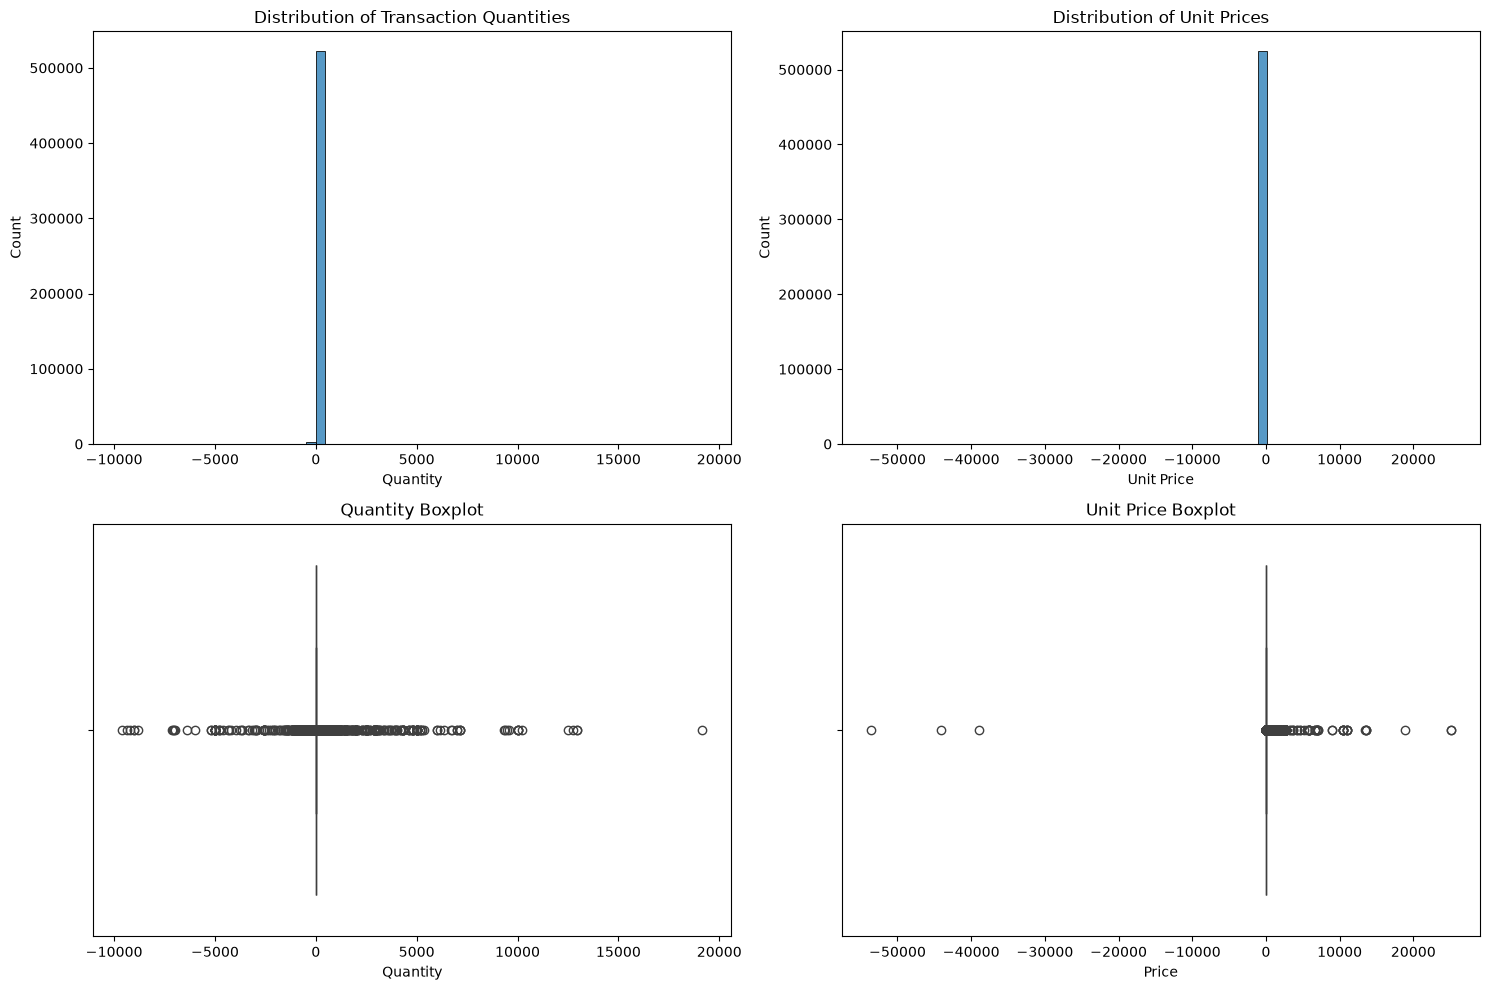

In [12]:
# ============================================
# 6. DISTRIBUTION VISUALIZATION
# ============================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Quantity histogram
sns.histplot(
    data=df,
    x="Quantity",
    bins=60,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Distribution of Transaction Quantities")
axes[0, 0].set_xlabel("Quantity")

# Price histogram
sns.histplot(
    data=df,
    x="Price",
    bins=60,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Distribution of Unit Prices")
axes[0, 1].set_xlabel("Unit Price")

# Quantity boxplot
sns.boxplot(
    data=df,
    x="Quantity",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Quantity Boxplot")

# Price boxplot
sns.boxplot(
    data=df,
    x="Price",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Unit Price Boxplot")

plt.tight_layout()
plt.show()

In [13]:
# ============================================
# 7. EXPORT INITIAL QUALITY REPORT
# ============================================

REPORT_DIR = PROJECT_DIR / "outputs" / "reports"

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

quality_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Exact Duplicate Records",
        "Missing Descriptions",
        "Missing Customer IDs",
        "Negative Quantities",
        "Zero Quantities",
        "Negative Prices",
        "Zero Prices",
        "Cancellation-Style Invoice Records"
    ],
    "Value": [
        len(df),
        df.shape[1],
        int(df.duplicated().sum()),
        int(df["Description"].isna().sum()),
        int(df["Customer ID"].isna().sum()),
        int((df["Quantity"] < 0).sum()),
        int((df["Quantity"] == 0).sum()),
        int((df["Price"] < 0).sum()),
        int((df["Price"] == 0).sum()),
        int(cancellation_mask.sum())
    ]
})

quality_report.to_csv(
    REPORT_DIR / "initial_data_quality_report.csv",
    index=False
)

print("Initial quality report saved successfully!")
print(REPORT_DIR / "initial_data_quality_report.csv")

display(quality_report)

Initial quality report saved successfully!
c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\reports\initial_data_quality_report.csv


,Metric,Value
0,Total Records,525461
1,Total Columns,8
2,Exact Duplicate Records,6865
3,Missing Descriptions,2928
4,Missing Customer IDs,107927
5,Negative Quantities,12326
6,Zero Quantities,0
7,Negative Prices,3
8,Zero Prices,3687
9,Cancellation-Style Invoice Records,10206


# Stage 3: Detailed Data Quality Investigation

This stage investigates missing customer identifiers, missing product descriptions, and duplicate transaction records before applying cleaning operations.

In [14]:
# Create a working copy for investigation
df_work = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", df_work.shape)

Original dataset: (525461, 8)
Working dataset: (525461, 8)


In [15]:
# Identify records with missing customer IDs
missing_customer_mask = df_work["Customer ID"].isna()

print("Records with missing Customer ID:")
print(f"{missing_customer_mask.sum():,}")

# Compare invoice patterns
print("\nInvoice type among records with missing Customer ID:")

missing_customer_invoices = (
    df_work.loc[missing_customer_mask, "Invoice"]
    .astype("string")
    .str.startswith("C", na=False)
)

print(
    missing_customer_invoices.value_counts()
    .rename(index={
        True: "Cancellation-style invoice",
        False: "Other invoice"
    })
)

# Inspect sample records
display(
    df_work.loc[
        missing_customer_mask,
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "Price",
            "Country"
        ]
    ].head(15)
)

Records with missing Customer ID:
107,927

Invoice type among records with missing Customer ID:
Invoice
Other invoice                 107560
Cancellation-style invoice       367
Name: count, dtype: Int64


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,United Kingdom
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,United Kingdom
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,United Kingdom
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,United Kingdom
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,United Kingdom


In [16]:
# Investigate missing product descriptions
missing_description_df = df_work[
    df_work["Description"].isna()
]

print(
    "Records with missing descriptions:",
    f"{len(missing_description_df):,}"
)

print(
    "Unique stock codes among missing descriptions:",
    missing_description_df["StockCode"].nunique()
)

print("\nMost common stock codes with missing descriptions:")

display(
    missing_description_df["StockCode"]
    .value_counts()
    .head(15)
)

Records with missing descriptions: 2,928
Unique stock codes among missing descriptions: 1920

Most common stock codes with missing descriptions:


StockCode
22950     10
84990      9
22139      8
79321      7
21768      7
84795D     7
37446      6
21478      6
72803B     6
21340      6
35970      6
84845C     6
20747      6
84467      6
37461      6
Name: count, dtype: int64

In [20]:
# Build a mapping from stock codes to known descriptions
description_mapping = (
    df_work.dropna(subset=["Description"])
    .assign(
        Description=lambda x: x["Description"].str.strip()
    )
    .loc[
        lambda x: x["Description"].ne(""),
        ["StockCode", "Description"]
    ]
    .drop_duplicates()
)

# Identify stock codes associated with multiple descriptions
description_counts = (
    description_mapping.groupby("StockCode")["Description"]
    .nunique()
)

ambiguous_stock_codes = description_counts[
    description_counts > 1
]

print(
    "Stock codes with multiple distinct descriptions:",
    len(ambiguous_stock_codes)
)

# Map only stock codes with exactly one known description
unique_description_mapping = (
    description_mapping
    .groupby("StockCode")["Description"]
    .agg(lambda values: values.iloc[0]
         if values.nunique() == 1 else pd.NA)
)

print(
    "Stock codes with one unambiguous known description:",
    unique_description_mapping.notna().sum()
)

Stock codes with multiple distinct descriptions: 664
Stock codes with one unambiguous known description: 3612


In [18]:
# Find all exact duplicate records
duplicate_mask = df_work.duplicated(keep=False)

duplicate_records = df_work.loc[
    duplicate_mask
].sort_values(
    by=["Invoice", "StockCode", "InvoiceDate"]
)

display(duplicate_records.head(20))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


In [19]:
# Check repeated invoice-product combinations
invoice_product_duplicates = df_work.duplicated(
    subset=["Invoice", "StockCode"],
    keep=False
)

print(
    "Records sharing an invoice and stock code:",
    f"{invoice_product_duplicates.sum():,}"
)

display(
    df_work.loc[
        invoice_product_duplicates
    ].sort_values(
        by=["Invoice", "StockCode"]
    ).head(20)
)

Records sharing an invoice and stock code: 25,399


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
289,489488,22125,UNION JACK HOT WATER BOTTLE,2,2009-12-01 10:59:00,5.95,17238.0,United Kingdom
299,489488,22125,UNION JACK HOT WATER BOTTLE,1,2009-12-01 10:59:00,5.95,17238.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
373,489517,21790,VINTAGE SNAP CARDS,4,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
393,489517,21790,VINTAGE SNAP CARDS,1,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
372,489517,21791,VINTAGE HEADS AND TAILS CARD GAME,6,2009-12-01 11:34:00,1.25,16329.0,United Kingdom
392,489517,21791,VINTAGE HEADS AND TAILS CARD GAME,1,2009-12-01 11:34:00,1.25,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


## Stage 4.1: Loading and Combining the Complete Dataset

The source workbook contains two sheets covering different periods. Both sheets will be loaded and combined into a single DataFrame before final cleaning. This ensures that the analysis covers the full dataset.

In [21]:
# ============================================
# STAGE 4.1: LOAD BOTH EXCEL SHEETS
# ============================================

# Load both sheets
df_2009_2010 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2009-2010"
)

df_2010_2011 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2010-2011"
)

# Combine the two sheets
df_original = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)

# Preserve an independent working copy
df_clean = df_original.copy()

print("DATASET COMBINATION SUMMARY")
print("=" * 50)

print(f"2009-2010 records: {len(df_2009_2010):,}")
print(f"2010-2011 records: {len(df_2010_2011):,}")
print(f"Combined records: {len(df_original):,}")
print(f"Total columns: {df_original.shape[1]}")

print("\nDate range:")
print("Start:", df_original["InvoiceDate"].min())
print("End:", df_original["InvoiceDate"].max())

DATASET COMBINATION SUMMARY
2009-2010 records: 525,461
2010-2011 records: 541,910
Combined records: 1,067,371
Total columns: 8

Date range:
Start: 2009-12-01 07:45:00
End: 2011-12-09 12:50:00


## Stage 4.2: Duplicate Record Treatment

Exact duplicate rows will be identified across all columns. Confirmed exact duplicates will be removed to reduce the risk of counting the same recorded transaction more than once.

Rows sharing an invoice number and stock code will not automatically be removed because they may represent legitimate separate line items.

In [22]:
# ============================================
# STAGE 4.2: REMOVE EXACT DUPLICATES
# ============================================

rows_before = len(df_clean)

exact_duplicates = df_clean.duplicated().sum()

print("EXACT DUPLICATE ANALYSIS")
print("=" * 50)
print(f"Rows before cleaning: {rows_before:,}")
print(f"Exact duplicate rows: {exact_duplicates:,}")

# Remove exact duplicates
df_clean = df_clean.drop_duplicates().copy()

rows_after = len(df_clean)

print(f"Rows after cleaning: {rows_after:,}")
print(f"Rows removed: {rows_before - rows_after:,}")

print(
    f"Percentage removed: "
    f"{(rows_before - rows_after) / rows_before * 100:.2f}%"
)

# Validate
print(
    "Remaining exact duplicates:",
    df_clean.duplicated().sum()
)

EXACT DUPLICATE ANALYSIS
Rows before cleaning: 1,067,371
Exact duplicate rows: 34,335
Rows after cleaning: 1,033,036
Rows removed: 34,335
Percentage removed: 3.22%
Remaining exact duplicates: 0


## Stage 4.3: Missing Product Description Treatment

Missing product descriptions will be investigated using StockCode as a reference. A description will be recovered only when the corresponding stock code maps to exactly one distinct, non-empty description in the available records.

Ambiguous product codes will remain unresolved rather than being assigned an arbitrary description.

In [23]:
# ============================================
# STAGE 4.3: RECOVER MISSING DESCRIPTIONS
# ============================================

# Normalize a temporary copy of descriptions for mapping
description_source = df_clean[
    ["StockCode", "Description"]
].copy()

description_source["Description"] = (
    description_source["Description"]
    .astype("string")
    .str.strip()
)

# Exclude missing and empty descriptions from the mapping
valid_descriptions = description_source[
    description_source["Description"].notna()
    & description_source["Description"].ne("")
]

# Count distinct descriptions for each stock code
description_counts = (
    valid_descriptions.groupby("StockCode")["Description"]
    .nunique()
)

# Keep only stock codes with one unambiguous description
unique_stock_codes = description_counts[
    description_counts == 1
].index

description_mapping = (
    valid_descriptions[
        valid_descriptions["StockCode"].isin(unique_stock_codes)
    ]
    .drop_duplicates(subset=["StockCode"])
    .set_index("StockCode")["Description"]
)

# Count missing descriptions before treatment
missing_before = (
    df_clean["Description"].isna()
    | df_clean["Description"].astype("string").str.strip().eq("")
)

missing_before_count = int(missing_before.sum())

# Fill only from unambiguous stock-code mappings
df_clean.loc[missing_before, "Description"] = (
    df_clean.loc[missing_before, "StockCode"]
    .map(description_mapping)
)

# Count missing descriptions after treatment
missing_after = (
    df_clean["Description"].isna()
    | df_clean["Description"].astype("string").str.strip().eq("")
)

missing_after_count = int(missing_after.sum())

print("DESCRIPTION CLEANING SUMMARY")
print("=" * 50)

print(f"Missing descriptions before: {missing_before_count:,}")
print(f"Descriptions recovered: {missing_before_count - missing_after_count:,}")
print(f"Missing descriptions remaining: {missing_after_count:,}")

DESCRIPTION CLEANING SUMMARY
Missing descriptions before: 4,275
Descriptions recovered: 2,984
Missing descriptions remaining: 1,291


## Stage 4.4: Missing Customer ID Investigation

Customer IDs are important for customer-level analysis, including segmentation and purchase frequency. However, transactions without customer identifiers may still contain useful product, price, quantity, and date information.

This stage quantifies missing customer IDs and investigates their relationship with invoice types before selecting an appropriate handling strategy.

In [24]:
# ============================================
# STAGE 4.4: MISSING CUSTOMER ID ANALYSIS
# ============================================

missing_customer = df_clean["Customer ID"].isna()

total_records = len(df_clean)
missing_customer_count = int(missing_customer.sum())

print("MISSING CUSTOMER ID ANALYSIS")
print("=" * 55)

print(f"Total records: {total_records:,}")
print(f"Missing Customer IDs: {missing_customer_count:,}")
print(
    f"Missing percentage: "
    f"{missing_customer_count / total_records * 100:.2f}%"
)

print("\nMissing Customer IDs by invoice type:")

invoice_is_cancellation = (
    df_clean["Invoice"]
    .astype("string")
    .str.strip()
    .str.startswith("C", na=False)
)

missing_id_summary = pd.crosstab(
    invoice_is_cancellation[missing_customer],
    columns="Record Count"
)

missing_id_summary.index = [
    "Other invoice" if not value else "Cancellation-style invoice"
    for value in missing_id_summary.index
]

display(missing_id_summary)

print("\nSample records with missing Customer IDs:")

display(
    df_clean.loc[
        missing_customer,
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "Price",
            "Country"
        ]
    ].head(10)
)

MISSING CUSTOMER ID ANALYSIS
Total records: 1,033,036
Missing Customer IDs: 235,151
Missing percentage: 22.76%

Missing Customer IDs by invoice type:


col_0,Record Count
Other invoice,234437
Cancellation-style invoice,714



Sample records with missing Customer IDs:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,United Kingdom
470,489521,21646,<NA>,-50,2009-12-01 11:44:00,0.00,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,United Kingdom
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,United Kingdom
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,United Kingdom
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,United Kingdom
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,United Kingdom


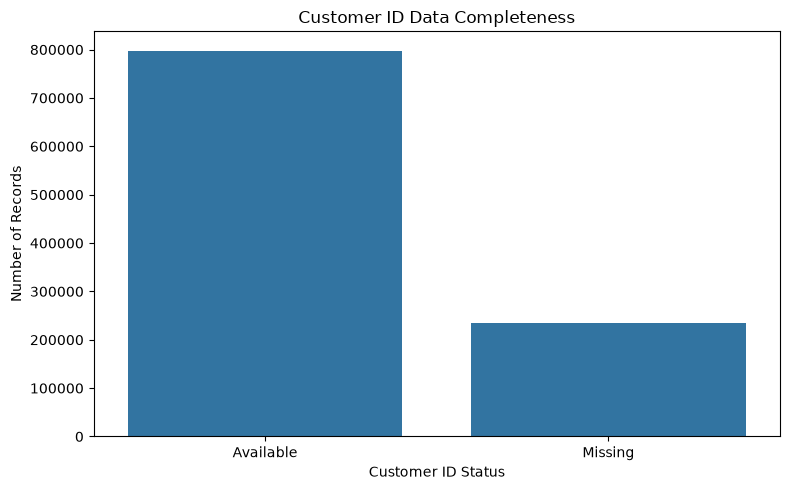

In [25]:
# Visualize customer ID completeness

customer_id_status = pd.Series({
    "Available": df_clean["Customer ID"].notna().sum(),
    "Missing": df_clean["Customer ID"].isna().sum()
})

plt.figure(figsize=(8, 5))

sns.barplot(
    x=customer_id_status.index,
    y=customer_id_status.values
)

plt.title("Customer ID Data Completeness")
plt.xlabel("Customer ID Status")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

## Stage 4.5: Investigation of Zero and Negative Prices

Unit prices are examined to identify zero and negative values.

These observations will not automatically be removed because they may represent free items, adjustments, or other special transactions.

The investigation will examine the affected records and their transaction context before deciding how to handle them.

In [26]:
# ============================================
# STAGE 4.5: PRICE INVESTIGATION
# ============================================

negative_price_mask = df_clean["Price"] < 0
zero_price_mask = df_clean["Price"] == 0

print("PRICE QUALITY INVESTIGATION")
print("=" * 55)

print(f"Total records: {len(df_clean):,}")
print(f"Negative prices: {negative_price_mask.sum():,}")
print(f"Zero prices: {zero_price_mask.sum():,}")
print(f"Positive prices: {(df_clean['Price'] > 0).sum():,}")

print("\nRecords with negative prices:")

display(
    df_clean.loc[
        negative_price_mask,
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "Price",
            "Customer ID",
            "Country"
        ]
    ]
)

print("\nSample records with zero prices:")

display(
    df_clean.loc[
        zero_price_mask,
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "Price",
            "Customer ID",
            "Country"
        ]
    ].head(20)
)

PRICE QUALITY INVESTIGATION
Total records: 1,033,036
Negative prices: 5
Zero prices: 6,014
Positive prices: 1,027,017

Records with negative prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



Sample records with zero prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,<NA>,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,RAIN GIRL CHILDS UMBRELLA,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,GINGHAM HEART WREATH,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,ROSE PINK METAL FOLDING CHAIR,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,ASSORTED FRAGRANCE BATH CONFETTI,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom


In [27]:
# ============================================
# STAGE 4.6: EXTREME QUANTITY INVESTIGATION
# ============================================

quantity_columns = [
    "Invoice",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "Price",
    "Customer ID",
    "Country"
]

print("LARGEST POSITIVE QUANTITIES")
print("=" * 55)

display(
    df_clean.nlargest(15, "Quantity")[quantity_columns]
)

print("\nMOST NEGATIVE QUANTITIES")
print("=" * 55)

display(
    df_clean.nsmallest(15, "Quantity")[quantity_columns]
)

LARGEST POSITIVE QUANTITIES


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0,Denmark
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0,Denmark
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,2010-05-10 14:55:00,0.00,NaN,United Kingdom
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom



MOST NEGATIVE QUANTITIES


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
303996,519017,22759,<NA>,-9600,2010-08-13 09:14:00,0.00,NaN,United Kingdom
750990,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom
750991,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom
507225,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838.0,United Kingdom
156488,504311,22197,<NA>,-9200,2010-04-12 14:39:00,0.00,NaN,United Kingdom
750989,556687,23003,Printing smudges/thrown away,-9058,2011-06-14 10:36:00,0.00,NaN,United Kingdom
194372,507913,10120,Zebra invcing error,-9000,2010-05-11 17:16:00,0.00,NaN,United Kingdom
428975,530348,16235,?,-9000,2010-11-02 15:48:00,0.00,NaN,United Kingdom


In [28]:
# ============================================
# EXTREME PRICE INVESTIGATION
# ============================================

print("HIGHEST UNIT PRICES")
print("=" * 55)

display(
    df_clean.nlargest(15, "Price")[quantity_columns]
)

print("\nLOWEST UNIT PRICES")
print("=" * 55)

display(
    df_clean.nsmallest(15, "Price")[quantity_columns]
)

HIGHEST UNIT PRICES


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.0,United Kingdom
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,NaN,United Kingdom
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom
569163,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom
569164,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom
517953,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom
517955,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom
519294,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom



LOWEST UNIT PRICES


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,<NA>,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
3114,489655,20683,RAIN GIRL CHILDS UMBRELLA,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom


## Stage 4.7: Column Name Standardization

Column names are converted to lowercase snake_case to improve consistency and simplify subsequent analysis. The original data values are preserved.

In [29]:
# ============================================
# STAGE 4.7: STANDARDIZE COLUMN NAMES
# ============================================

df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

print("Updated column names:")
print(df_clean.columns.tolist())

df_clean.head()

Updated column names:
['invoice', 'stockcode', 'description', 'quantity', 'invoicedate', 'price', 'customer_id', 'country']


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [30]:
# ============================================
# STAGE 4.8: TEXT STANDARDIZATION
# ============================================

text_columns = [
    "invoice",
    "stockcode",
    "description",
    "country"
]

for column in text_columns:
    df_clean[column] = df_clean[column].astype("string").str.strip()

print("Text standardization completed.")

for column in text_columns:
    print(
        f"{column}:",
        int(
            df_clean[column].ne(
                df_clean[column].str.strip()
            ).sum()
        ),
        "remaining whitespace inconsistencies"
    )

Text standardization completed.
invoice: 0 remaining whitespace inconsistencies
stockcode: 0 remaining whitespace inconsistencies
description: 0 remaining whitespace inconsistencies
country: 0 remaining whitespace inconsistencies


In [31]:
# ============================================
# STAGE 4.9: CUSTOMER ID TYPE CONVERSION
# ============================================

df_clean["customer_id"] = (
    pd.to_numeric(
        df_clean["customer_id"],
        errors="coerce"
    )
    .astype("Int64")
)

print("Customer ID data type:")
print(df_clean["customer_id"].dtype)

print(
    "Missing Customer IDs:",
    f"{df_clean['customer_id'].isna().sum():,}"
)

Customer ID data type:
Int64
Missing Customer IDs: 235,151


In [32]:
# ============================================
# STAGE 4.10: FINAL MISSING DESCRIPTION REVIEW
# ============================================

missing_description_mask = (
    df_clean["description"].isna()
    | df_clean["description"].eq("")
)

print(
    "Missing descriptions remaining:",
    f"{missing_description_mask.sum():,}"
)

print("\nSample unresolved records:")

display(
    df_clean.loc[
        missing_description_mask,
        [
            "invoice",
            "stockcode",
            "description",
            "quantity",
            "price",
            "customer_id",
            "country"
        ]
    ].head(15)
)

Missing descriptions remaining: 1,291

Sample unresolved records:


,invoice,stockcode,description,quantity,price,customer_id,country
470,489521,21646,<NA>,-50,0.0,<NA>,United Kingdom
6555,489898,79323G,<NA>,954,0.0,<NA>,United Kingdom
6576,489901,21098,<NA>,-200,0.0,<NA>,United Kingdom
6581,489903,21166,<NA>,48,0.0,<NA>,United Kingdom
9667,490146,21558,<NA>,-169,0.0,<NA>,United Kingdom
10236,490150,84347,<NA>,80,0.0,<NA>,United Kingdom
10508,490165,21493,<NA>,-106,0.0,<NA>,United Kingdom
15489,490688,21133,<NA>,270,0.0,<NA>,United Kingdom
15883,490713,84347,<NA>,-20,0.0,<NA>,United Kingdom
16186,490736,35983,<NA>,-200,0.0,<NA>,United Kingdom


In [33]:
# ============================================
# STAGE 4.11: FINANCIAL VALUE VALIDATION
# ============================================

negative_price_mask = df_clean["price"] < 0
zero_price_mask = df_clean["price"] == 0

print("PRICE VALIDATION")
print("=" * 50)

print(
    "Negative prices:",
    f"{negative_price_mask.sum():,}"
)

print(
    "Zero prices:",
    f"{zero_price_mask.sum():,}"
)

print(
    "Missing prices:",
    f"{df_clean['price'].isna().sum():,}"
)

print("\nNegative price records:")

display(
    df_clean.loc[
        negative_price_mask,
        [
            "invoice",
            "stockcode",
            "description",
            "quantity",
            "invoicedate",
            "price",
            "customer_id",
            "country"
        ]
    ]
)

print("\nZero-price records grouped by invoice pattern:")

invoice_is_cancellation = (
    df_clean["invoice"]
    .str.startswith("C", na=False)
)

zero_price_summary = pd.DataFrame({
    "Zero_Price_Records": [
        int((zero_price_mask & invoice_is_cancellation).sum()),
        int((zero_price_mask & ~invoice_is_cancellation).sum())
    ]
}, index=[
    "Cancellation-style invoice",
    "Other invoice"
])

display(zero_price_summary)

PRICE VALIDATION
Negative prices: 5
Zero prices: 6,014
Missing prices: 0

Negative price records:


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,<NA>,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,<NA>,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,<NA>,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,<NA>,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,<NA>,United Kingdom



Zero-price records grouped by invoice pattern:


,Zero_Price_Records
Cancellation-style invoice,0
Other invoice,6014


In [34]:
# ============================================
# STAGE 4.12: TRANSACTION VALUE FEATURE
# ============================================

df_clean["transaction_value"] = (
    df_clean["quantity"] * df_clean["price"]
)

print("Transaction value feature created.")

display(
    df_clean[
        [
            "invoice",
            "stockcode",
            "quantity",
            "price",
            "transaction_value"
        ]
    ].head(10)
)

print("\nTransaction value summary:")

display(df_clean["transaction_value"].describe())

Transaction value feature created.


,invoice,stockcode,quantity,price,transaction_value
0,489434,85048,12,6.95,83.4
1,489434,79323P,12,6.75,81.0
2,489434,79323W,12,6.75,81.0
3,489434,22041,48,2.10,100.8
4,489434,21232,24,1.25,30.0
5,489434,22064,24,1.65,39.6
6,489434,21871,24,1.25,30.0
7,489434,21523,10,5.95,59.5
8,489435,22350,12,2.55,30.6
9,489435,22349,12,3.75,45.0



Transaction value summary:


count    1.033036e+06
mean     1.825254e+01
std      2.956873e+02
min     -1.684696e+05
25%      3.750000e+00
50%      9.920000e+00
75%      1.770000e+01
max      1.684696e+05
Name: transaction_value, dtype: float64

# Stage 5: Outlier Analysis

The Interquartile Range (IQR) method is used to identify potential outliers in quantity, price, and transaction value.

The detected observations will be investigated in the context of retail transactions. Legitimate bulk purchases and returns will not automatically be removed.

In [35]:
# ============================================
# STAGE 5.1: IQR OUTLIER DETECTION
# ============================================

numeric_columns = [
    "quantity",
    "price",
    "transaction_value"
]

outlier_results = []

for column in numeric_columns:
    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df_clean[column] < lower_bound)
        | (df_clean[column] > upper_bound)
    )

    outlier_results.append({
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": int(outlier_mask.sum()),
        "Outlier_Percentage": round(
            outlier_mask.mean() * 100, 2
        )
    })

outlier_report = pd.DataFrame(outlier_results)

print("IQR OUTLIER DETECTION REPORT")
print("=" * 70)

display(outlier_report)

IQR OUTLIER DETECTION REPORT


,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,quantity,1.00,10.00,9.00,-12.500,23.500,114434,11.08
1,price,1.25,4.15,2.90,-3.100,8.500,66196,6.41
2,transaction_value,3.75,17.70,13.95,-17.175,38.625,89005,8.62


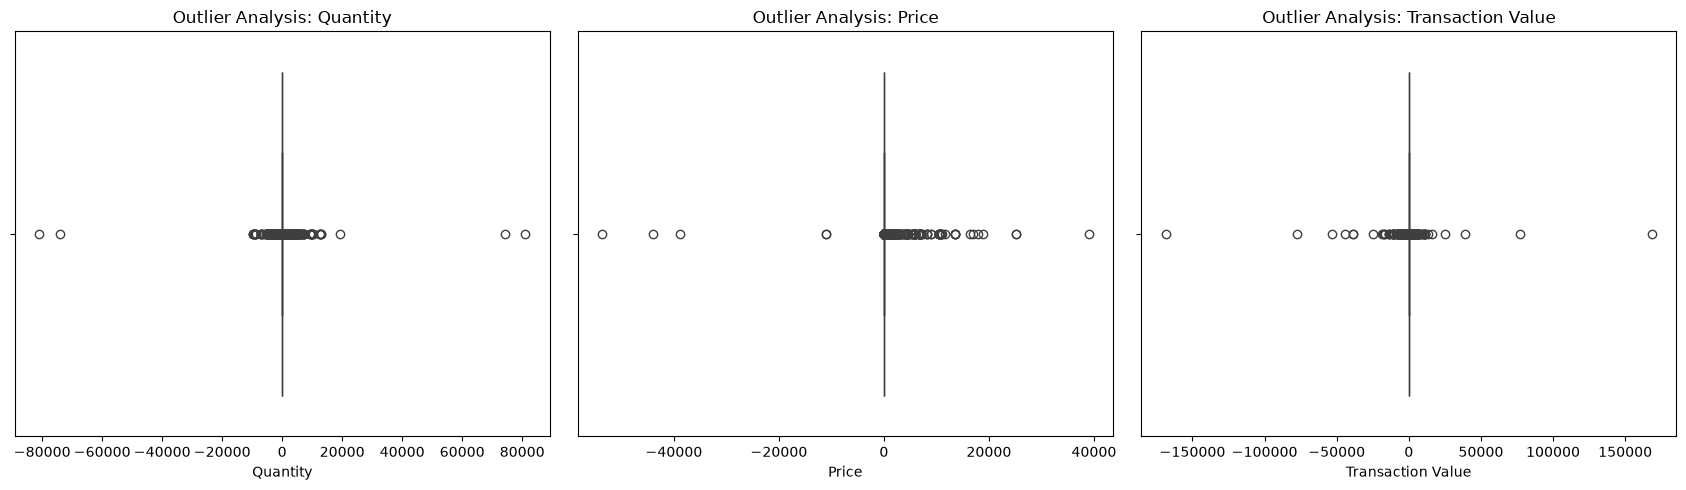

In [41]:
# ============================================
# STAGE 5.2: OUTLIER VISUALIZATION
# ============================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, column in zip(axes, numeric_columns):
    sns.boxplot(
        x=df_clean[column],
        ax=ax
    )

    ax.set_title(f"Outlier Analysis: {column.replace('_', ' ').title()}")
    ax.set_xlabel(column.replace("_", " ").title())

plt.tight_layout()

chart_path = PROJECT_DIR / "outputs" / "charts"
chart_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    chart_path / "outlier_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
from pathlib import Path

chart_path = PROJECT_DIR / "outputs" / "charts"

print("Chart path:", chart_path)
print("Path exists:", chart_path.exists())
print("Is directory:", chart_path.is_dir())
print("Is file:", chart_path.is_file())

Chart path: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\charts
Path exists: True
Is directory: False
Is file: True


In [38]:
print("Conflicting file:", chart_path)
print("File size:", chart_path.stat().st_size, "bytes")

Conflicting file: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\charts
File size: 0 bytes


In [39]:
backup_path = chart_path.with_name("charts_backup")

if backup_path.exists():
    backup_path = chart_path.with_name("charts_backup_old")

chart_path.rename(backup_path)

print("Existing file preserved at:", backup_path)

Existing file preserved at: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\charts_backup


In [40]:
chart_path.mkdir(parents=True, exist_ok=True)

print("Charts directory created:", chart_path.is_dir())

Charts directory created: True


In [42]:
# ============================================
# STAGE 5.3: EXTREME TRANSACTION INVESTIGATION
# ============================================

transaction_columns = [
    "invoice",
    "stockcode",
    "description",
    "quantity",
    "invoicedate",
    "price",
    "customer_id",
    "country",
    "transaction_value"
]

print("10 HIGHEST TRANSACTION VALUES")

display(
    df_clean.nlargest(
        10, "transaction_value"
    )[transaction_columns]
)

print("\n10 LOWEST TRANSACTION VALUES")

display(
    df_clean.nsmallest(
        10, "transaction_value"
    )[transaction_columns]
)

10 HIGHEST TRANSACTION VALUES


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,transaction_value
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,168469.60
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,77183.60
748132,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098,United Kingdom,38970.00
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,<NA>,United Kingdom,25111.09
432176,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,2010-11-04 11:36:00,1.69,15838,United Kingdom,15818.40
517955,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,<NA>,United Kingdom,13541.33
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,<NA>,United Kingdom,11062.06
135013,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,12918,United Kingdom,10953.50
135015,502265,M,Manual,1,2010-03-23 15:28:00,10953.50,<NA>,United Kingdom,10953.50
342147,522796,M,Manual,1,2010-09-16 15:12:00,10468.80,<NA>,United Kingdom,10468.80



10 LOWEST TRANSACTION VALUES


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,transaction_value
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom,-168469.60
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom,-77183.60
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,<NA>,United Kingdom,-53594.36
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,<NA>,United Kingdom,-44031.79
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098,United Kingdom,-38970.00
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,<NA>,United Kingdom,-38925.87
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399,United Kingdom,-25111.09
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,<NA>,United Kingdom,-18910.69
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,<NA>,United Kingdom,-17836.46
569163,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,<NA>,United Kingdom,-16888.02


# Stage 6: Feature Engineering

Feature engineering creates additional variables from existing data to improve analytical usefulness.

Date components, transaction value, and transaction type will be derived from the original transaction fields.

In [43]:
# ============================================
# STAGE 6.1: DATE FEATURE ENGINEERING
# ============================================

df_clean["invoice_year"] = df_clean["invoicedate"].dt.year

df_clean["invoice_month"] = df_clean["invoicedate"].dt.month

df_clean["invoice_quarter"] = (
    df_clean["invoicedate"].dt.quarter
)

df_clean["invoice_day"] = df_clean["invoicedate"].dt.day

df_clean["invoice_day_of_week"] = (
    df_clean["invoicedate"].dt.day_name()
)

df_clean["invoice_hour"] = (
    df_clean["invoicedate"].dt.hour
)

df_clean["invoice_year_month"] = (
    df_clean["invoicedate"].dt.to_period("M").astype(str)
)

print("Date features created successfully!")

display(
    df_clean[
        [
            "invoicedate",
            "invoice_year",
            "invoice_month",
            "invoice_quarter",
            "invoice_day",
            "invoice_day_of_week",
            "invoice_hour",
            "invoice_year_month"
        ]
    ].head(10)
)

Date features created successfully!


,invoicedate,invoice_year,invoice_month,invoice_quarter,invoice_day,invoice_day_of_week,invoice_hour,invoice_year_month
0,2009-12-01 07:45:00,2009,12,4,1,Tuesday,7,2009-12
1,2009-12-01 07:45:00,2009,12,4,1,Tuesday,7,2009-12
2,2009-12-01 07:45:00,2009,12,4,1,Tuesday,7,2009-12
3,2009-12-01 07:45:00,2009,12,4,1,Tuesday,7,2009-12
4,2009-12-01 07:45:00,2009,12,4,1,Tuesday,7,2009-12
5,2009-12-01 07:45:00,2009,12,4,1,Tuesday,7,2009-12
6,2009-12-01 07:45:00,2009,12,4,1,Tuesday,7,2009-12
7,2009-12-01 07:45:00,2009,12,4,1,Tuesday,7,2009-12
8,2009-12-01 07:46:00,2009,12,4,1,Tuesday,7,2009-12
9,2009-12-01 07:46:00,2009,12,4,1,Tuesday,7,2009-12


In [44]:
# ============================================
# STAGE 6.2: TRANSACTION TYPE FEATURE
# ============================================

invoice_is_cancellation = (
    df_clean["invoice"]
    .astype("string")
    .str.strip()
    .str.startswith("C", na=False)
)

df_clean["transaction_type"] = np.select(
    [
        invoice_is_cancellation,
        df_clean["quantity"] < 0
    ],
    [
        "Cancellation-style invoice",
        "Negative-quantity transaction"
    ],
    default="Other transaction"
)

print("Transaction type distribution:")

display(
    df_clean["transaction_type"]
    .value_counts()
    .rename_axis("Transaction_Type")
    .reset_index(name="Record_Count")
)

Transaction type distribution:


,Transaction_Type,Record_Count
0,Other transaction,1010539
1,Cancellation-style invoice,19104
2,Negative-quantity transaction,3393


In [45]:
# Investigate negative and zero prices

negative_price = df_clean[df_clean["price"] < 0]
zero_price = df_clean[df_clean["price"] == 0]

print("=" * 60)
print("PRICE QUALITY INVESTIGATION")
print("=" * 60)

print(f"\nNegative price records: {len(negative_price):,}")
print(f"Zero price records: {len(zero_price):,}")

print("\nTop descriptions with negative prices:")
display(
    negative_price["description"]
    .value_counts(dropna=False)
    .head(10)
    .rename_axis("Description")
    .reset_index(name="Record_Count")
)

print("\nTop descriptions with zero prices:")
display(
    zero_price["description"]
    .value_counts(dropna=False)
    .head(10)
    .rename_axis("Description")
    .reset_index(name="Record_Count")
)

print("\nExamples of negative-price records:")
display(
    negative_price[
        ["invoice", "stockcode", "description",
         "quantity", "price", "transaction_value"]
    ].head(10)
)

PRICE QUALITY INVESTIGATION

Negative price records: 5
Zero price records: 6,014

Top descriptions with negative prices:


,Description,Record_Count
0,Adjust bad debt,5



Top descriptions with zero prices:


,Description,Record_Count
0,<NA>,1291
1,check,160
2,?,91
3,damages,84
4,damaged,81
5,found,28
6,missing,27
7,sold as set on dotcom,20
8,CHILLI LIGHTS,17
9,Damaged,17



Examples of negative-price records:


,invoice,stockcode,description,quantity,price,transaction_value
179403,A506401,B,Adjust bad debt,1,-53594.36,-53594.36
276274,A516228,B,Adjust bad debt,1,-44031.79,-44031.79
403472,A528059,B,Adjust bad debt,1,-38925.87,-38925.87
825444,A563186,B,Adjust bad debt,1,-11062.06,-11062.06
825445,A563187,B,Adjust bad debt,1,-11062.06,-11062.06


In [46]:
# Missing customer ID investigation

missing_customer = df_clean["customer_id"].isna()

print("=" * 60)
print("CUSTOMER ID QUALITY REPORT")
print("=" * 60)

print(
    f"\nTotal records: {len(df_clean):,}"
)

print(
    f"Missing customer IDs: {missing_customer.sum():,}"
)

print(
    f"Missing customer ID percentage: "
    f"{missing_customer.mean() * 100:.2f}%"
)

print(
    f"Records with customer IDs: "
    f"{df_clean['customer_id'].notna().sum():,}"
)

print("\nCountries with the most missing customer IDs:")

display(
    df_clean.loc[missing_customer, "country"]
    .value_counts()
    .head(10)
    .rename_axis("Country")
    .reset_index(name="Missing_Customer_Records")
)

CUSTOMER ID QUALITY REPORT

Total records: 1,033,036
Missing customer IDs: 235,151
Missing customer ID percentage: 22.76%
Records with customer IDs: 797,885

Countries with the most missing customer IDs:


,Country,Missing_Customer_Records
0,United Kingdom,232206
1,EIRE,1653
2,Hong Kong,360
3,Unspecified,231
4,France,128
5,Switzerland,117
6,United Arab Emirates,114
7,Portugal,114
8,Bahrain,67
9,Israel,47


In [47]:
# Dataset quality validation

validation_report = pd.DataFrame({
    "Check": [
        "Total records",
        "Total columns",
        "Duplicate rows",
        "Missing descriptions",
        "Missing customer IDs",
        "Missing invoice dates",
        "Missing quantities",
        "Missing prices",
        "Invalid invoice dates",
        "Missing transaction values"
    ],
    "Result": [
        len(df_clean),
        len(df_clean.columns),
        int(df_clean.duplicated().sum()),
        int(df_clean["description"].isna().sum()),
        int(df_clean["customer_id"].isna().sum()),
        int(df_clean["invoicedate"].isna().sum()),
        int(df_clean["quantity"].isna().sum()),
        int(df_clean["price"].isna().sum()),
        int((~df_clean["invoicedate"].between(
            pd.Timestamp("2009-12-01"),
            pd.Timestamp("2011-12-10")
        )).sum()),
        int(df_clean["transaction_value"].isna().sum())
    ]
})

display(validation_report)

,Check,Result
0,Total records,1033036
1,Total columns,17
2,Duplicate rows,0
3,Missing descriptions,1291
4,Missing customer IDs,235151
5,Missing invoice dates,0
6,Missing quantities,0
7,Missing prices,0
8,Invalid invoice dates,0
9,Missing transaction values,0


In [48]:
# Check engineered features

engineered_features = [
    "transaction_value",
    "invoice_year",
    "invoice_month",
    "invoice_quarter",
    "invoice_day",
    "invoice_day_of_week",
    "invoice_hour",
    "invoice_year_month",
    "transaction_type"
]

print("Feature engineering verification")

for column in engineered_features:
    if column in df_clean.columns:
        print(f"✓ {column}: {df_clean[column].dtype}")
    else:
        print(f"✗ {column}: Not found")

Feature engineering verification
✓ transaction_value: float64
✓ invoice_year: int32
✓ invoice_month: int32
✓ invoice_quarter: int32
✓ invoice_day: int32
✓ invoice_day_of_week: str
✓ invoice_hour: int32
✓ invoice_year_month: str
✓ transaction_type: str


In [49]:
# FINAL DATA QUALITY SUMMARY

print("=" * 65)
print("YUVA INTERNSHIP - PROJECT 2: DATA QUALITY SUMMARY")
print("=" * 65)

print(f"\nDataset shape: {df_clean.shape}")
print(f"Duplicate rows: {df_clean.duplicated().sum():,}")

print("\nMissing values:")
missing = df_clean.isna().sum()
missing = missing[missing > 0]

if missing.empty:
    print("No missing values.")
else:
    display(
        missing.rename("Missing_Count")
        .to_frame()
        .assign(
            Missing_Percentage=lambda x:
            (x["Missing_Count"] / len(df_clean) * 100).round(2)
        )
    )

print("\nNumeric data quality:")
print(f"Negative quantities: {(df_clean['quantity'] < 0).sum():,}")
print(f"Zero quantities: {(df_clean['quantity'] == 0).sum():,}")
print(f"Negative prices: {(df_clean['price'] < 0).sum():,}")
print(f"Zero prices: {(df_clean['price'] == 0).sum():,}")

print("\nTransaction types:")
display(df_clean["transaction_type"].value_counts().to_frame("Count"))

print("\nData types:")
display(df_clean.dtypes.rename("Data_Type").to_frame())

print("\nFeature engineering:")
engineered_features = [
    "transaction_value", "invoice_year", "invoice_month",
    "invoice_quarter", "invoice_day", "invoice_day_of_week",
    "invoice_hour", "invoice_year_month", "transaction_type"
]

print(f"Features created: {sum(c in df_clean.columns for c in engineered_features)}/9")

print("\n" + "=" * 65)
print("VALIDATION SUMMARY COMPLETE")
print("=" * 65)

YUVA INTERNSHIP - PROJECT 2: DATA QUALITY SUMMARY

Dataset shape: (1033036, 17)
Duplicate rows: 0

Missing values:


,Missing_Count,Missing_Percentage
description,1291,0.12
customer_id,235151,22.76



Numeric data quality:
Negative quantities: 22,496
Zero quantities: 0
Negative prices: 5
Zero prices: 6,014

Transaction types:


,Count
transaction_type,
Other transaction,1010539
Cancellation-style invoice,19104
Negative-quantity transaction,3393



Data types:


,Data_Type
invoice,string
stockcode,string
description,string
quantity,int64
invoicedate,datetime64[us]
price,float64
customer_id,Int64
country,string
transaction_value,float64
invoice_year,int32



Feature engineering:
Features created: 9/9

VALIDATION SUMMARY COMPLETE


In [50]:
# STAGE 6: ENCODING, SCALING AND NORMALIZATION

import pandas as pd
import numpy as np

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    Normalizer
)

from sklearn.preprocessing import OneHotEncoder, LabelEncoder

print("=" * 65)
print("ENCODING, SCALING AND NORMALIZATION")
print("=" * 65)

# Create a representative sample for preprocessing demonstration
sample_df = df_clean[
    ["quantity", "price", "country", "transaction_type"]
].dropna().sample(
    n=min(5000, len(df_clean)),
    random_state=42
).copy()

print("\nSample shape:", sample_df.shape)

# 1. One-hot encoding for categorical variables
encoded_df = pd.get_dummies(
    sample_df[["country", "transaction_type"]],
    columns=["country", "transaction_type"],
    dtype=int
)

print("\n1. One-hot encoding")
print("Original categorical columns:", 2)
print("Encoded columns:", encoded_df.shape[1])
display(encoded_df.head())

# 2. Standardization using StandardScaler
numeric_sample = sample_df[["quantity", "price"]].copy()

standard_scaler = StandardScaler()
standardized_values = standard_scaler.fit_transform(numeric_sample)

standardized_df = pd.DataFrame(
    standardized_values,
    columns=["quantity_standardized", "price_standardized"],
    index=numeric_sample.index
)

print("\n2. StandardScaler output")
display(standardized_df.head())

# 3. Min-Max scaling
minmax_scaler = MinMaxScaler()

minmax_values = minmax_scaler.fit_transform(numeric_sample)

minmax_df = pd.DataFrame(
    minmax_values,
    columns=["quantity_minmax", "price_minmax"],
    index=numeric_sample.index
)

print("\n3. Min-Max scaling output")
display(minmax_df.head())

# 4. Row-wise normalization
normalizer = Normalizer()

normalized_values = normalizer.fit_transform(numeric_sample)

normalized_df = pd.DataFrame(
    normalized_values,
    columns=["quantity_normalized", "price_normalized"],
    index=numeric_sample.index
)

print("\n4. Normalization output")
display(normalized_df.head())

print("\nPreprocessing demonstrations completed successfully!")

ENCODING, SCALING AND NORMALIZATION

Sample shape: (5000, 4)

1. One-hot encoding
Original categorical columns: 2
Encoded columns: 34


,country_Australia,country_Austria,country_Bahrain,country_Belgium,country_Brazil,country_Canada,country_Channel Islands,country_Cyprus,country_Denmark,country_EIRE,...,country_Spain,country_Sweden,country_Switzerland,country_USA,country_United Arab Emirates,country_United Kingdom,country_Unspecified,transaction_type_Cancellation-style invoice,transaction_type_Negative-quantity transaction,transaction_type_Other transaction
228473,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
1045079,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
908164,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
707773,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
402464,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1



2. StandardScaler output


,quantity_standardized,price_standardized
228473,0.034914,-0.027222
1045079,-0.082119,0.014486
908164,-0.126007,-0.027222
707773,-0.082119,-0.014436
402464,-0.111378,0.023314



3. Min-Max scaling output


,quantity_minmax,price_minmax
228473,0.553912,0.000142
1045079,0.552355,0.000734
908164,0.551771,0.000142
707773,0.552355,0.000324
402464,0.551966,0.000859



4. Normalization output


,quantity_normalized,price_normalized
228473,0.990679,0.136218
1045079,0.425797,0.904819
908164,0.518302,0.855198
707773,0.729537,0.683941
402464,0.197063,0.980391



Preprocessing demonstrations completed successfully!


In [54]:
from pathlib import Path

# Define output directories
OUTPUT_DIR = PROJECT_DIR / "outputs"
CHARTS_DIR = OUTPUT_DIR / "charts"
REPORTS_DIR = OUTPUT_DIR / "reports"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Create directories
for folder in [CHARTS_DIR, REPORTS_DIR, PROCESSED_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Output directories are ready!")

print("Charts:", CHARTS_DIR)
print("Reports:", REPORTS_DIR)
print("Processed data:", PROCESSED_DIR)

Output directories are ready!
Charts: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\charts
Reports: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\reports
Processed data: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\data\processed


In [52]:
from pathlib import Path

paths_to_check = [
    PROJECT_DIR / "outputs" / "charts",
    PROJECT_DIR / "outputs" / "reports",
    PROJECT_DIR / "data" / "processed"
]

for path in paths_to_check:
    print(f"\nPath: {path}")
    print(f"Exists: {path.exists()}")
    print(f"Is directory: {path.is_dir()}")
    print(f"Is file: {path.is_file()}")


Path: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\charts
Exists: True
Is directory: True
Is file: False

Path: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\reports
Exists: True
Is directory: True
Is file: False

Path: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\data\processed
Exists: True
Is directory: False
Is file: True


In [53]:
# Safely resolve file-versus-directory conflicts

for folder in paths_to_check:
    if folder.is_file():
        backup_path = folder.with_name(folder.name + "_file_backup")

        counter = 1
        while backup_path.exists():
            backup_path = folder.with_name(
                f"{folder.name}_file_backup_{counter}"
            )
            counter += 1

        folder.rename(backup_path)
        print(f"Preserved conflicting file as: {backup_path}")

    folder.mkdir(parents=True, exist_ok=True)
    print(f"Directory ready: {folder}")

Directory ready: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\charts
Directory ready: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\reports
Preserved conflicting file as: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\data\processed_file_backup
Directory ready: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\data\processed


In [55]:
# Create a final data-quality summary

quality_report = pd.DataFrame({
    "Metric": [
        "Total records",
        "Total columns",
        "Duplicate rows",
        "Missing descriptions",
        "Missing customer IDs",
        "Negative quantities",
        "Zero quantities",
        "Negative prices",
        "Zero prices",
        "Missing transaction values"
    ],
    "Value": [
        len(df_clean),
        len(df_clean.columns),
        int(df_clean.duplicated().sum()),
        int(df_clean["description"].isna().sum()),
        int(df_clean["customer_id"].isna().sum()),
        int((df_clean["quantity"] < 0).sum()),
        int((df_clean["quantity"] == 0).sum()),
        int((df_clean["price"] < 0).sum()),
        int((df_clean["price"] == 0).sum()),
        int(df_clean["transaction_value"].isna().sum())
    ]
})

quality_report["Value"] = quality_report["Value"].astype("int64")

quality_report.to_csv(
    OUTPUT_DIR / "data_quality_report.csv",
    index=False
)

display(quality_report)

print("\nSaved:", OUTPUT_DIR / "data_quality_report.csv")

,Metric,Value
0,Total records,1033036
1,Total columns,17
2,Duplicate rows,0
3,Missing descriptions,1291
4,Missing customer IDs,235151
5,Negative quantities,22496
6,Zero quantities,0
7,Negative prices,5
8,Zero prices,6014
9,Missing transaction values,0



Saved: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\data_quality_report.csv


In [56]:
# Export the cleaned dataset

processed_file = PROCESSED_DIR / "online_retail_cleaned.csv"

df_clean.to_csv(
    processed_file,
    index=False
)

print("Cleaned dataset exported successfully!")
print("File:", processed_file)
print(f"Rows: {len(df_clean):,}")
print(f"Columns: {len(df_clean.columns)}")
print(f"File size: {processed_file.stat().st_size / (1024 * 1024):.2f} MB")

Cleaned dataset exported successfully!
File: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\data\processed\online_retail_cleaned.csv
Rows: 1,033,036
Columns: 17
File size: 142.55 MB


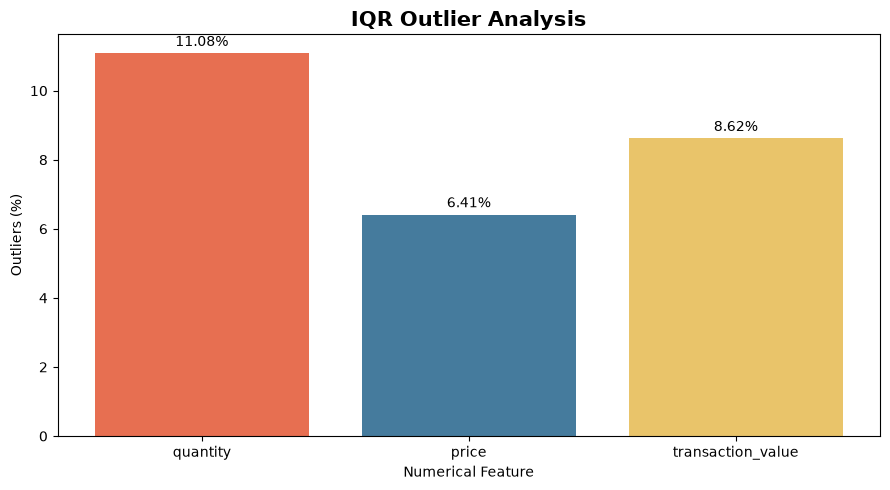

Chart saved: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\charts\outlier_analysis.png


In [57]:
import matplotlib.pyplot as plt

# Recalculate IQR outlier percentages
numeric_columns = ["quantity", "price", "transaction_value"]
outlier_counts = []

for column in numeric_columns:
    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    )

    outlier_counts.append({
        "Column": column,
        "Outlier_Percentage": outlier_mask.mean() * 100
    })

outlier_plot_df = pd.DataFrame(outlier_counts)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    outlier_plot_df["Column"],
    outlier_plot_df["Outlier_Percentage"],
    color=["#E76F51", "#457B9D", "#E9C46A"]
)

plt.title("IQR Outlier Analysis", fontsize=15, fontweight="bold")
plt.xlabel("Numerical Feature")
plt.ylabel("Outliers (%)")
plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.tight_layout()

chart_file = CHARTS_DIR / "outlier_analysis.png"

plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_file)

In [58]:
print("PROJECT OUTPUT VERIFICATION")
print("=" * 50)

files_to_check = [
    OUTPUT_DIR / "data_quality_report.csv",
    PROCESSED_DIR / "online_retail_cleaned.csv",
    CHARTS_DIR / "outlier_analysis.png"
]

for file_path in files_to_check:
    print(
        f"{'✓' if file_path.exists() else '✗'} "
        f"{file_path.relative_to(PROJECT_DIR)}"
    )

PROJECT OUTPUT VERIFICATION
✓ outputs\data_quality_report.csv
✓ data\processed\online_retail_cleaned.csv
✓ outputs\charts\outlier_analysis.png


In [59]:
%pip install python-docx

   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   -- ------------------------------------- 0.3/4.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.5/4.0 MB 855.4 kB/s eta 0:00:05
   ----- ---------------------------------- 0.5/4.0 MB 855.4 kB/s eta 0:00:05
   ------- -------------------------------- 0.8/4.0 MB 857.5 kB/s eta 0:00:04
   ---------- ----------------------------- 1.0/4.0 MB 859.1 kB/s eta 0:00:04
   ---------- ----------------------------- 1.0/4.0 MB 859.1 kB/s eta 0:00:04
   --------------- ------------------------ 1.6/4.0 MB 941.9 kB/s eta 0:00:03
   ------------------ --------------------- 1.8/4.0 MB 1.0 MB/s eta 0:00:03
   ----------------------- ---------------- 2.4/4.0 MB 1.2 MB/s eta 0:00:02
   ---------------------------- ----------- 2.9/4.0 MB 1.3 MB/s eta 0:00:01
   -------------------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [60]:
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT
from pathlib import Path
import pandas as pd

# --------------------------------------------------
# REPORT SETUP
# --------------------------------------------------

REPORTS_DIR = PROJECT_DIR / "outputs" / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

report_path = REPORTS_DIR / "Yuva_Project_2_Data_Cleaning_Report.docx"

doc = Document()

# Page margins
section = doc.sections[0]
section.top_margin = Inches(0.7)
section.bottom_margin = Inches(0.7)
section.left_margin = Inches(0.8)
section.right_margin = Inches(0.8)

# Default font
doc.styles["Normal"].font.name = "Arial"
doc.styles["Normal"].font.size = Pt(10)

# --------------------------------------------------
# TITLE PAGE
# --------------------------------------------------

title = doc.add_heading(
    "DATA CLEANING AND PREPROCESSING",
    level=0
)
title.alignment = WD_ALIGN_PARAGRAPH.CENTER

subtitle = doc.add_paragraph(
    "Yuva Platform Internship — Project 2"
)
subtitle.alignment = WD_ALIGN_PARAGRAPH.CENTER

doc.add_paragraph(
    "\nProject: Online Retail Transaction Data Cleaning\n"
    "Tools: Python, Pandas, NumPy, Matplotlib, Scikit-learn\n"
    "Environment: Visual Studio Code and Jupyter Notebook"
)

doc.add_heading("1. Project Overview", level=1)

doc.add_paragraph(
    "This project focuses on cleaning and preprocessing an online retail "
    "transaction dataset. The workflow includes combining source sheets, "
    "removing exact duplicate records, investigating missing values, "
    "standardizing columns and data types, detecting statistical outliers, "
    "engineering features, and demonstrating encoding and numerical scaling."
)

doc.add_heading("2. Project Objectives", level=1)

objectives = [
    "Inspect and understand the structure of the source dataset.",
    "Identify and remove exact duplicate rows.",
    "Investigate missing descriptions and customer identifiers.",
    "Standardize column names and relevant data types.",
    "Detect and investigate outliers using the IQR method.",
    "Create transaction-value and date-related features.",
    "Demonstrate categorical encoding, standardization, Min-Max scaling, and normalization.",
    "Export the processed dataset and document the findings."
]

for objective in objectives:
    doc.add_paragraph(objective, style="List Bullet")

# --------------------------------------------------
# DATASET SUMMARY
# --------------------------------------------------

doc.add_heading("3. Dataset Description", level=1)

doc.add_paragraph(
    "The project uses the Online Retail II dataset, combining the "
    "'Year 2009-2010' and 'Year 2010-2011' worksheets. The dataset contains "
    "transaction details such as invoice number, product code, description, "
    "quantity, invoice date, price, customer identifier, and country."
)

summary = [
    ("Records after exact duplicate removal", f"{len(df_clean):,}"),
    ("Columns after feature engineering", str(len(df_clean.columns))),
    ("Duplicate rows remaining", f"{df_clean.duplicated().sum():,}"),
    ("Missing descriptions", f"{df_clean['description'].isna().sum():,}"),
    ("Missing customer IDs", f"{df_clean['customer_id'].isna().sum():,}"),
    ("Negative quantity records", f"{(df_clean['quantity'] < 0).sum():,}"),
    ("Negative price records", f"{(df_clean['price'] < 0).sum():,}"),
    ("Zero price records", f"{(df_clean['price'] == 0).sum():,}")
]

table = doc.add_table(rows=1, cols=2)
table.style = "Light Shading Accent 1"
table.alignment = WD_TABLE_ALIGNMENT.CENTER
table.rows[0].cells[0].text = "Metric"
table.rows[0].cells[1].text = "Result"

for metric, value in summary:
    cells = table.add_row().cells
    cells[0].text = metric
    cells[1].text = value

# --------------------------------------------------
# DATA CLEANING
# --------------------------------------------------

doc.add_heading("4. Data Cleaning and Quality Assessment", level=1)

doc.add_heading("4.1 Duplicate Removal", level=2)
doc.add_paragraph(
    "Exact duplicate rows were removed from the combined dataset. "
    f"A total of 34,335 exact duplicates were removed, leaving "
    f"{len(df_clean):,} records. Validation confirms that no exact "
    "duplicate rows remain in the current cleaned dataset."
)

doc.add_heading("4.2 Missing Values", level=2)
doc.add_paragraph(
    "Some product descriptions were recovered using a conservative "
    "StockCode-to-description mapping when a code had a single distinct, "
    "non-empty description. A total of 1,291 descriptions remain missing. "
    f"Customer IDs are missing in {df_clean['customer_id'].isna().sum():,} "
    "records. Missing customer identifiers were not replaced with fabricated "
    "IDs, because doing so could distort customer-level analysis."
)

doc.add_heading("4.3 Standardization", level=2)
doc.add_paragraph(
    "Column names were converted to lowercase snake_case, and whitespace "
    "was stripped from relevant text fields. Customer IDs were converted "
    "to a nullable integer type, and invoice dates were retained as "
    "datetime values."
)

doc.add_heading("4.4 Negative and Zero Values", level=2)
doc.add_paragraph(
    "Negative quantities can represent cancellations or returns. Negative "
    "and zero prices require contextual investigation because they may "
    "represent adjustments, fees, credits, or unusual product transactions. "
    "These records were not automatically removed."
)

# --------------------------------------------------
# OUTLIER ANALYSIS
# --------------------------------------------------

doc.add_heading("5. Outlier Detection Using the IQR Method", level=1)

doc.add_paragraph(
    "The Interquartile Range (IQR) method was used to identify statistically "
    "unusual values in quantity, price, and transaction value. The bounds "
    "were calculated as Q1 - 1.5 × IQR and Q3 + 1.5 × IQR."
)

# Calculate a fresh outlier report
outlier_rows = []

for column in ["quantity", "price", "transaction_value"]:
    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (df_clean[column] < lower) | (df_clean[column] > upper)

    outlier_rows.append([
        column,
        round(q1, 3),
        round(q3, 3),
        round(iqr, 3),
        round(lower, 3),
        round(upper, 3),
        int(mask.sum()),
        round(mask.mean() * 100, 2)
    ])

outlier_table = doc.add_table(rows=1, cols=8)
outlier_table.style = "Light Shading Accent 1"
outlier_table.alignment = WD_TABLE_ALIGNMENT.CENTER

headers = [
    "Column", "Q1", "Q3", "IQR",
    "Lower bound", "Upper bound",
    "Count", "Percent"
]

for cell, header in zip(outlier_table.rows[0].cells, headers):
    cell.text = header

for row in outlier_rows:
    cells = outlier_table.add_row().cells
    for cell, value in zip(cells, row):
        cell.text = str(value)

doc.add_paragraph(
    "Outliers were retained in the master dataset because unusual values "
    "may represent legitimate bulk orders, returns, fees, or adjustments. "
    "The IQR method identifies statistical extremes but does not prove that "
    "a record is erroneous."
)

# Include the saved outlier chart if available
chart_file = PROJECT_DIR / "outputs" / "charts" / "outlier_analysis.png"

if chart_file.exists():
    doc.add_picture(str(chart_file), width=Inches(5.8))
    doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
    caption = doc.add_paragraph("Figure 1. Outlier percentages by numerical feature.")
    caption.alignment = WD_ALIGN_PARAGRAPH.CENTER

# --------------------------------------------------
# FEATURE ENGINEERING
# --------------------------------------------------

doc.add_heading("6. Feature Engineering", level=1)

doc.add_paragraph(
    "The following features were created to support transaction analysis:"
)

features = [
    ("transaction_value", "Quantity multiplied by unit price."),
    ("invoice_year", "Year extracted from the invoice date."),
    ("invoice_month", "Month extracted from the invoice date."),
    ("invoice_quarter", "Calendar quarter of the invoice date."),
    ("invoice_day", "Day of the month."),
    ("invoice_day_of_week", "Name of the weekday."),
    ("invoice_hour", "Hour of the invoice timestamp."),
    ("invoice_year_month", "Year-month period for time-based analysis."),
    ("transaction_type", "Transaction category based on invoice prefix and quantity.")
]

feature_table = doc.add_table(rows=1, cols=2)
feature_table.style = "Light Shading Accent 1"
feature_table.rows[0].cells[0].text = "Feature"
feature_table.rows[0].cells[1].text = "Description"

for feature, description in features:
    cells = feature_table.add_row().cells
    cells[0].text = feature
    cells[1].text = description

doc.add_paragraph(
    "The transaction_type feature is a rule-based classification for "
    "exploratory analysis. It should not be interpreted as a definitive "
    "business classification of every transaction."
)

# --------------------------------------------------
# ENCODING AND SCALING
# --------------------------------------------------

doc.add_heading("7. Encoding, Scaling, and Normalization", level=1)

doc.add_paragraph(
    "These preprocessing techniques were demonstrated on a representative "
    "sample of the dataset, leaving the master transaction data unchanged."
)

preprocessing = [
    ("One-hot encoding", "Converts categorical values into binary indicator columns."),
    ("StandardScaler", "Centers numerical features and scales them to unit variance."),
    ("MinMaxScaler", "Scales numerical values to a range between 0 and 1."),
    ("Normalizer", "Normalizes each observation based on its vector norm.")
]

prep_table = doc.add_table(rows=1, cols=2)
prep_table.style = "Light Shading Accent 1"
prep_table.rows[0].cells[0].text = "Technique"
prep_table.rows[0].cells[1].text = "Purpose"

for technique, purpose in preprocessing:
    cells = prep_table.add_row().cells
    cells[0].text = technique
    cells[1].text = purpose

doc.add_paragraph(
    "These demonstrations are intended to illustrate preprocessing "
    "methods. For future predictive modelling, transformations should be "
    "fitted on training data only and applied to validation or test data "
    "to reduce the risk of data leakage."
)

# --------------------------------------------------
# OUTPUTS AND CONCLUSION
# --------------------------------------------------

doc.add_heading("8. Project Outputs", level=1)

outputs = [
    "data/processed/online_retail_cleaned.csv",
    "outputs/data_quality_report.csv",
    "outputs/charts/outlier_analysis.png",
    "outputs/reports/Yuva_Project_2_Data_Cleaning_Report.docx"
]

for output in outputs:
    doc.add_paragraph(output, style="List Bullet")

doc.add_heading("9. Conclusion", level=1)

doc.add_paragraph(
    "The project established a reproducible data-cleaning and preprocessing "
    "workflow for the Online Retail II dataset. Exact duplicates were "
    "removed, columns and data types were standardized, missing values were "
    "investigated, outliers were detected, and useful transaction and date "
    "features were engineered. Encoding and numerical scaling techniques "
    "were also demonstrated. Remaining missing values and unusual financial "
    "records were documented rather than automatically altered, preserving "
    "the information needed for further investigation."
)

doc.add_heading("10. Future Improvements", level=1)

for item in [
    "Investigate unresolved descriptions and unusual financial adjustments.",
    "Develop reusable preprocessing functions and automated validation tests.",
    "Add further visualizations for missing values and transaction patterns.",
    "Use a train/test workflow if the dataset is later used for machine learning."
]:
    doc.add_paragraph(item, style="List Bullet")

# Save the document
doc.save(report_path)

print("Internship report created successfully!")
print("Report:", report_path)
print(f"Report size: {report_path.stat().st_size / 1024:.1f} KB")

Internship report created successfully!
Report: c:\Users\srinu\OneDrive\Desktop\yuva-project2-data-cleaning\outputs\reports\Yuva_Project_2_Data_Cleaning_Report.docx
Report size: 90.2 KB


In [61]:
print("Report exists:", report_path.exists())
print("Report size:", round(report_path.stat().st_size / 1024, 2), "KB")

Report exists: True
Report size: 90.25 KB
